# 01 · Flesch Reading Ease

**Does the easier-scoring opening win more often in the published training pairs?** Flesch Reading Ease is `206.835 − 1.015 × words per sentence − 84.6 × syllables per word`. Higher scores indicate easier surface reading. We use the same approximate sentence boundaries and syllable rules in all three conditions.

| Condition | How we treat the archived text |
| --- | --- |
| Raw | Score the body as stored. |
| Minimal · primary | Decode HTML entities, remove quoted blocks and URLs, and strip common Markdown markers while preserving link labels. |
| Expanded | Start with Minimal, then expand a fixed list of internet shorthand. |

Syllable counts use the first CMU pronunciation when available, with English hyphenation as a fallback. Flesch measures surface readability. Assessing the clarity of the reasoning calls for reading the replies. All comparisons use the same complete pairs and preserve the opening word count from the prior length analysis for checking length effects. The published outcome is the branch's eventual delta. [Flesch's original paper](https://pubmed.ncbi.nlm.nih.gov/18867058/)

The [standalone script](analyze_flesch.py) saves timestamped runs. To regenerate in this kernel, install `cmudict==1.1.3` and `pyphen==0.18.1` if needed, then run the notebook or script.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "team-setup").is_dir() and (p / "pyproject.toml").is_file()
)
RUNS = REPO / "project/data/processed/linguistic-features/flesch"
SCRIPT = REPO / "project/notebooks/linguistic-features/readability/analyze_flesch.py"
RUN_ID = None
runs = sorted(RUNS.glob("*/results.json"))
if RUN_ID is None and not runs:
    subprocess.run([sys.executable, str(SCRIPT)], check=True)
    runs = sorted(RUNS.glob("*/results.json"))
report_path = RUNS / RUN_ID / "results.json" if RUN_ID else runs[-1]
report = json.loads(report_path.read_text())
pairs = pd.read_parquet(report_path.parent / "paired_scores.parquet")
openings = pd.read_parquet(report_path.parent / "opening_scores.parquet")

# Use each unique opening once for distribution summaries and feature correlations.
variants = ["raw", "minimal", "expanded"]
opening_ids = pd.unique(pairs[["a_comment_id", "b_comment_id"]].to_numpy().ravel())
openings = openings.loc[opening_ids]
print(f"{len(pairs):,} complete training pairs · {len(openings):,} unique openings "
      f"· {report['discussions']:,} OP discussions")
print(f"{report['published_pairs']:,} published pairs · "
      f"{report['shared_pairs'] - len(pairs):,} lost at Flesch scoring after opening checks")

3,451 complete training pairs · 6,581 unique openings · 2,507 OP discussions
3,456 published pairs · 0 lost at Flesch scoring after opening checks


## Score distributions and cleaning changes

Negative values and values above 100 are possible. Large shifts can reflect long punctuation-free passages, quotation removal, URLs, or abbreviation handling. Compare opening rank correlation, the number of A/B order reversals, and ties gained or lost. These describe sensitivity to preprocessing.

In [2]:
display(openings[variants].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2))
display(pd.DataFrame(report["cleaning_shifts"]).set_index("comparison").round(3))

# Inspect the largest raw-to-minimal changes without mixing them with the blind review.
shift = (openings["minimal"] - openings["raw"]).rename("minimal_minus_raw")
extremes = shift.abs().nlargest(5).index
display(openings.loc[extremes, ["word_count", *variants]].join(shift).round(2))

,raw,minimal,expanded
count,6581.00,6581.00,6581.00
mean,59.33,60.05,60.06
std,12.30,12.11,12.11
min,-17.05,-17.05,-17.05
1%,26.96,27.88,27.88
25%,51.44,52.36,52.36
50%,60.13,60.74,60.75
75%,67.81,68.42,68.42
99%,84.89,85.04,85.03
max,98.18,100.65,100.65


,median_shift,median_absolute_shift,opening_rank_spearman,pair_order_reversals,ties_changed
comparison,,,,,
raw → minimal,0.0,0.0,0.972,171,0
minimal → expanded,0.0,0.0,1.000,6,0


,word_count,raw,minimal,expanded,minimal_minus_raw
comment_id,,,,,
t1_cabbfp2,221,-6.39,37.67,37.67,44.06
t1_chdrzfe,101,28.76,-13.78,-13.78,-42.54
t1_ckfcgxf,110,17.06,52.15,52.15,35.09
t1_cnaozch,49,68.80,36.60,36.60,-32.21
t1_chyajv3,158,29.86,59.66,59.66,29.80


## Winner-higher rates and standalone prediction

The descriptive comparison uses unequal scores and reports ties separately. The 95% interval resamples whole OP discussions. The close-length check keeps pairs whose opening word counts differ by at most 50 words.

For prediction, use the shared randomized A/B assignment and predict whether A won from `Flesch_A − Flesch_B`. The same three discussion-grouped folds apply across all conditions. ROC-AUC is the primary predictive metric. Average precision has the A-wins prevalence as a reference. The length correlation uses unique openings.

In [3]:
rows = []
close = []
for result in report["metrics"]:
    near = result["near_length"]
    rows.append({
        "condition": result["variant"], "pairs": result["pairs"], "ties": result["ties"],
        "winner_higher_pct": 100 * result["winner_higher_rate"],
        "CI lower_pct": 100 * result["ci_95"][0], "CI upper_pct": 100 * result["ci_95"][1],
        "Spearman vs word count": result["spearman_with_word_count"],
        "ROC-AUC": result["roc_auc"], "Average precision": result["average_precision"],
    })
    close.append({
        "condition": result["variant"], "pairs": near["pairs"], "ties": near["ties"],
        "winner_higher_pct": 100 * near["winner_higher_rate"],
        "CI lower_pct": 100 * near["ci_95"][0], "CI upper_pct": 100 * near["ci_95"][1],
    })
results = pd.DataFrame(rows).set_index("condition")
close_length = pd.DataFrame(close).set_index("condition")
display(results.round(4))
print("Pairs within 50 opening words")
display(close_length.round(3))
print(f"A-wins prevalence: {report['metrics'][0]['a_win_prevalence']:.2%}")

,pairs,ties,winner_higher_pct,CI lower_pct,CI upper_pct,Spearman vs word count,ROC-AUC,Average precision
condition,,,,,,,,
raw,3451,1,43.9710,42.2541,45.7239,-0.0624,0.5753,0.5565
minimal,3451,1,45.4493,43.7372,47.3613,-0.0678,0.5610,0.5391
expanded,3451,1,45.5072,43.7680,47.4204,-0.0675,0.5611,0.5391


Pairs within 50 opening words


,pairs,ties,winner_higher_pct,CI lower_pct,CI upper_pct
condition,,,,,
raw,1144,1,44.619,41.487,47.640
minimal,1144,1,47.157,43.887,50.218
expanded,1144,1,47.244,43.995,50.307


A-wins prevalence: 49.67%


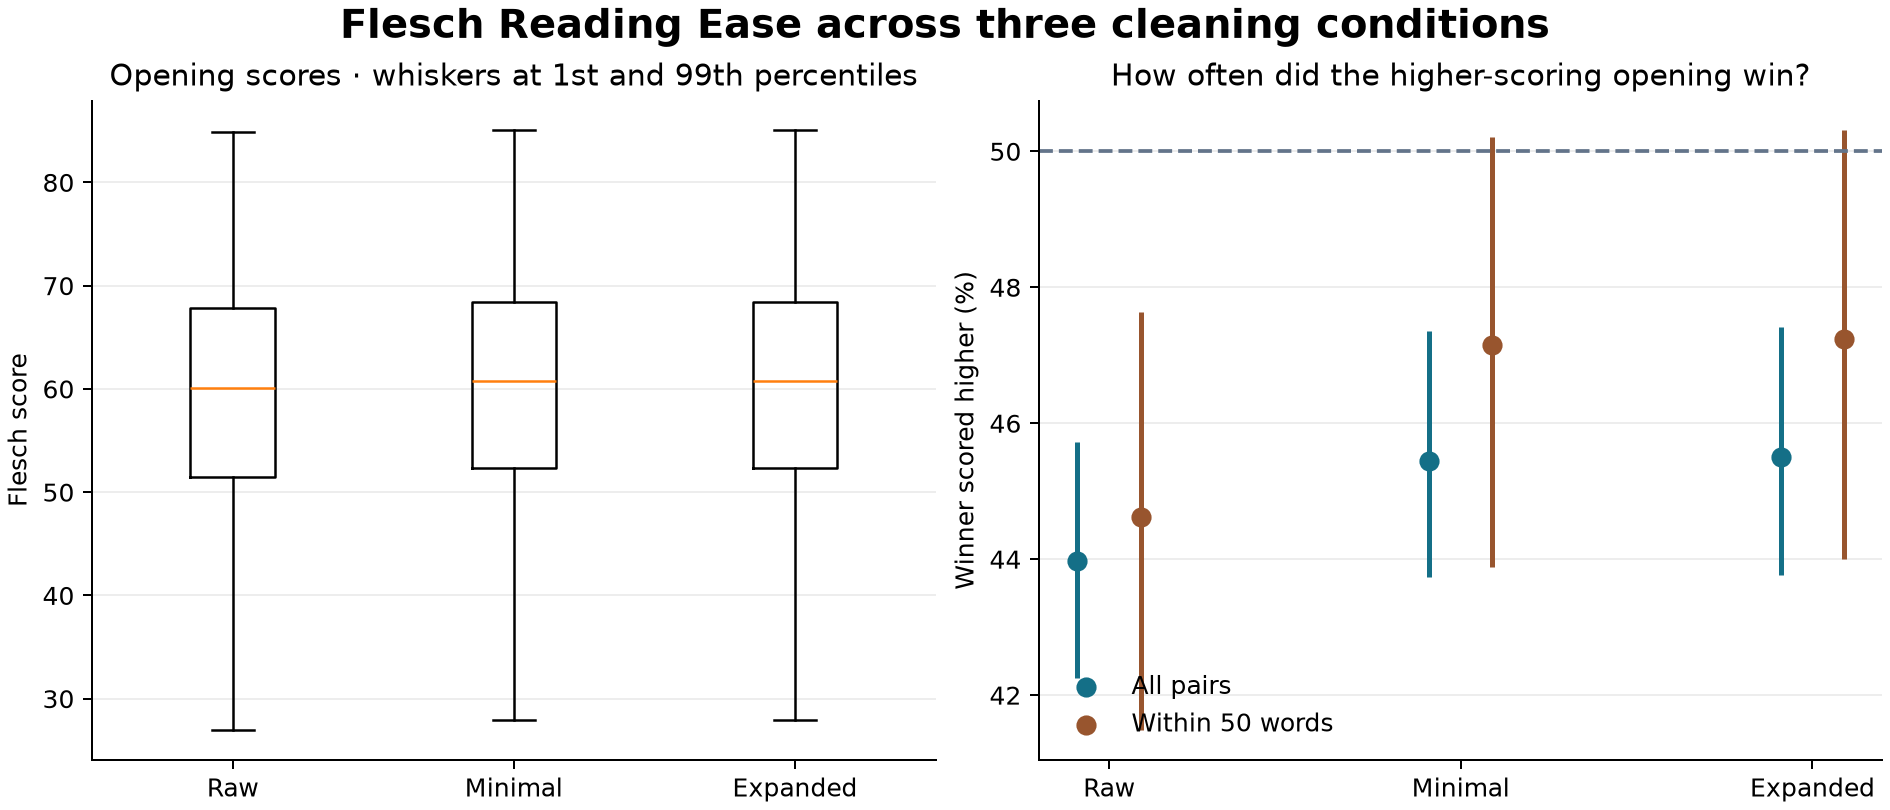

In [4]:
import matplotlib.pyplot as plt

fig, (distribution, win_share) = plt.subplots(1, 2, figsize=(10.5, 4.5), layout="constrained")
fig.suptitle("Flesch Reading Ease across three cleaning conditions", weight="bold", fontsize=16)
distribution.boxplot([openings[name] for name in variants], whis=(1, 99), showfliers=False)
distribution.set_xticks([1, 2, 3], ["Raw", "Minimal", "Expanded"])
distribution.set(title="Opening scores · whiskers at 1st and 99th percentiles", ylabel="Flesch score")

x = np.arange(len(variants))
for table, offset, color, label in [
    (results, -0.09, "#146f87", "All pairs"),
    (close_length, 0.09, "#98552e", "Within 50 words"),
]:
    win_share.vlines(x + offset, table["CI lower_pct"], table["CI upper_pct"], color=color, lw=2)
    win_share.scatter(x + offset, table["winner_higher_pct"], color=color, s=50, label=label, zorder=3)
win_share.axhline(50, linestyle="--", color="#63748a")
win_share.set_xticks(x, ["Raw", "Minimal", "Expanded"])
win_share.set(title="How often did the higher-scoring opening win?", ylabel="Winner scored higher (%)")
win_share.legend(frameon=False, loc="best")
for ax in (distribution, win_share):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)
fig.savefig(report_path.parent / "flesch_comparison.png", dpi=180, facecolor="white")
plt.show()

## Blind review

Read A and B in each case and mark which one makes its main point easier to follow. The sample mixes cases where Raw and Minimal disagree on score order with cases where they agree. The table hides which cases belong to each group, the model scores, and the delta labels. If a distinction is unclear, mark a tie and note the sentence, term, or formatting that affected your judgment.

After recording judgments, choose a case to inspect all three text versions. The final cell optionally reveals the scores and outcomes. The sample illustrates failure modes. Its composition was chosen for review.

In [5]:
review = pd.read_parquet(report_path.parent / "blind_review.parquet")
with pd.option_context("display.max_colwidth", None):
    display(review.set_index("case"))

,opening_A,opening_B
case,,
1,"&gt;Therefore, **anything that cannot be determined to have a clear winner should not be considered a sport.** Even if you don't accept this definition, there is a clear difference between artistic activities and athletic activities. Athletic events require mostly physical fitness and coordination, and have a clear winner. Artistic events, like marching band and dance, may require physical activity, but mostly utilize one's creative interpretation. Additionally, artistic events cannot be judged objectively, and artistic competitions almost always have judges who use their own subjection to determine the winners.\n\nSo in Boxing and MMA when it comes to a decision at the end of the match, does that make those two events non sports?\n\nYesterday The Cincinnati Bengals tied the Carolina Panthers, was this not a sport since there was no winner? \n\nThe ladies on the cheer and dance teams are some of the most physically fit people on the field, and are noticeably more fit, than anyone on the offensive line, and more-so than DTs.","If judged sports such as figure skating, gymnastics, and diving are considered sports and even allowed in the Olympics, then dance can be a sport too. Dance is actually similar to any of these judged sports. It's individually done (can be group, too), judged by people, and a scoring system can be created, hence the one with most points win. Rhythmic gymnastics is very dancey, and it's in the Olympics.\n\nIf golf is considered a sport despite no physical strain, then marching band can be turned into a sport too. Teams compete against each other, people judge their routines, they accumulate points, and a winner is determined. Same for cheerleading. \n\nIn other words, pretty much anything can be turned into a sport if they can be judged and assigned points. Competitive eating can be a sport too despite no physical strain. Heck, curling has been reinstated as a sport back into the Olympics!"
2,"How would you remove the profit motive and still incentivise companies to compete with each other? The risk of what you're suggesting (government control of companies, regulated profit margins) is that you end up with less efficiency, consumer choice, and higher prices. All the downsides of Soviet-style communism.\n\nAlso, I believe forcing companies to stay would not work. Companies are made of people after all and preventing people from leaving is not practical. Without a profit motive for laborers to stay you'd end up with assets but no workers.\n\nThe documentary [*The Corporation*](https://www.youtube.com/watch?v=KMNZXV7jOG0) makes a very compelling case supporting your premise, but instead of making the corporations into slaves of the state, they suggest revoking the corporate charter of any corporation who is found to be working against the interests of society. I believe such an approach would work better.","I would argue that there is no human model of intelligence that can describe the singlemindedness of a corporate charter, sociopathy or otherwise.\n\nInstead, I would describe for-profit businesses as something the AI community calls a [""paperclip maximizer""](http://wiki.lesswrong.com/wiki/Paperclip_maximizer). A singleminded intelligence that can and eventually will destroy everything else in order to produce more of what it exists to produce.\n\nThat is far more terrifying than any mere malfunction of the human mind."
3,"Because [happier employees get more done](http://www.inc.com/jessica-stillman/happy-employees-are-more-productive-employees.html). Sick employees are even less productive. So if I'm feeling burnt out at my job because I don't get to take a vacation, I'm going to slack off more at work while I find a new and better job, which brings me to my second point.\n\nOther employers are willing to give paid sick leave and vacation time and you have to compete with them for the workforce. Presumably you're not looking to hire a person for fun, you have a job you nee

In [6]:
# Pick a case to compare the text changes without revealing scores or outcomes.
INSPECT_CASE = None
if INSPECT_CASE is not None:
    case_text = review.set_index("case").loc[INSPECT_CASE]
    pair_id = pd.read_parquet(
        report_path.parent / "review_key.parquet", columns=["case", "pair_id"]
    ).set_index("case").at[INSPECT_CASE, "pair_id"]
    pair = pairs.set_index("pair_id").loc[pair_id]
    for side in ("A", "B"):
        opening = openings.loc[pair[f"{side.lower()}_comment_id"]]
        print(f"{side} · Raw\n{case_text[f'opening_{side}']}\n")
        print(f"{side} · Minimal\n{opening['minimal_text']}\n")
        print(f"{side} · Expanded\n{opening['expanded_text']}\n")

In [7]:
# Reveal only after making your judgments. Set to True and run this cell when ready.
REVEAL = False
if REVEAL:
    display(pd.read_parquet(report_path.parent / "review_key.parquet").set_index("case").round(2))